# Forecasting California Gasoline Prices — Time-Series Models and Forecasts

This notebook follows the Methodology of the *Project Proposal: Forecasting California Gasoline Prices* step by step:

| Section | Contents | Proposal |
|---|---|---|
| 0 | Setup, load `data/weekly_data.csv` | 1. Data preparation |
| 1 | EDA: prices, CA–U.S. spread, STL, ADF/KPSS, ACF/PACF, does crude lead gasoline? | 2. Exploratory analysis |
| 2 | Train/test split + rolling-origin backtest framework | 3. Test design |
| 3 | Conventional models: naive, seasonal naive, ETS, ARIMA + Fourier, ARIMAX | 4. Conventional models |
| 4 | Evaluation: MAE/RMSE/MAPE, skill vs naive, Diebold-Mariano, 80% interval coverage, forecast combination | 6. Evaluation |
| 5 | VAR, Granger causality, impulse response | 4. VAR |
| 6 | Rockets and feathers: asymmetric error-correction model | 4. Asymmetry test |
| 3.5, 7 | **AI models**: Chronos, TimesFM, LLMs (Claude, ChatGPT); AI vs conventional models | 5. AI models |
| 8 | **Scenario forecasts**: with vs without events (war, refinery outage), Brent price scenarios with `scenario()` | 7. Dashboard scenario tool |

**Run `data_pull.py` first** to create `data/weekly_data.csv`. Every model's forecasts are saved in the shared format from the proposal:
`model, origin_date, horizon, target_date, forecast, lower80, upper80` (in `forecasts/`).

## 0. Setup and data

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("data/weekly_data.csv")
FC_DIR = Path("forecasts"); FC_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

TRAIN_END = "2025-06-30"   # last training week (proposal: train Jan 2000 - Jun 2025)
H = 12                     # forecast 1-12 weeks ahead
SCORE_H = [4, 12]          # horizons we score
Z80 = stats.norm.ppf(0.9)  # 80% interval -> +/- 1.2816 sd
PERIOD = 365.25 / 7        # weekly seasonal period (~52.18)

df = pd.read_csv(DATA, index_col="date", parse_dates=True).asfreq("W-MON")
print(df.shape, df.index.min().date(), "->", df.index.max().date())
df.tail(3)

(1377, 22) 2000-05-22 -> 2026-10-05


,ca_gas,us_gas,wti,brent,refinery_util_padd5,gas_stocks_padd5,refinery_util_us,gas_stocks_us,spread,log_ca_gas,...,log_brent,summer_blend,july_tax,covid,p66_la_closed,benicia_closed,chevron_es_fire,iraq_war,ukraine_war,iran_war_2026
date,,,,,,,,,,,,,,,,,,,,,
2026-09-21,6.003,4.478,103.542,124.146,94.9,27386,96.8,207732,1.525,1.792259,...,4.821458,1,0,0,1,1,0,0,0,1
2026-09-28,6.189,4.465,93.574,117.084,94.5,27328,94.0,206046,1.724,1.822774,...,4.762892,1,0,0,1,1,0,0,0,1
2026-10-05,6.227,4.354,98.074,120.034,93.4,27990,92.5,204362,1.873,1.828895,...,4.787775,1,0,0,1,1,0,0,0,1


## 1. Exploratory analysis
### 1.1 California vs U.S. prices, the spread, and crude oil

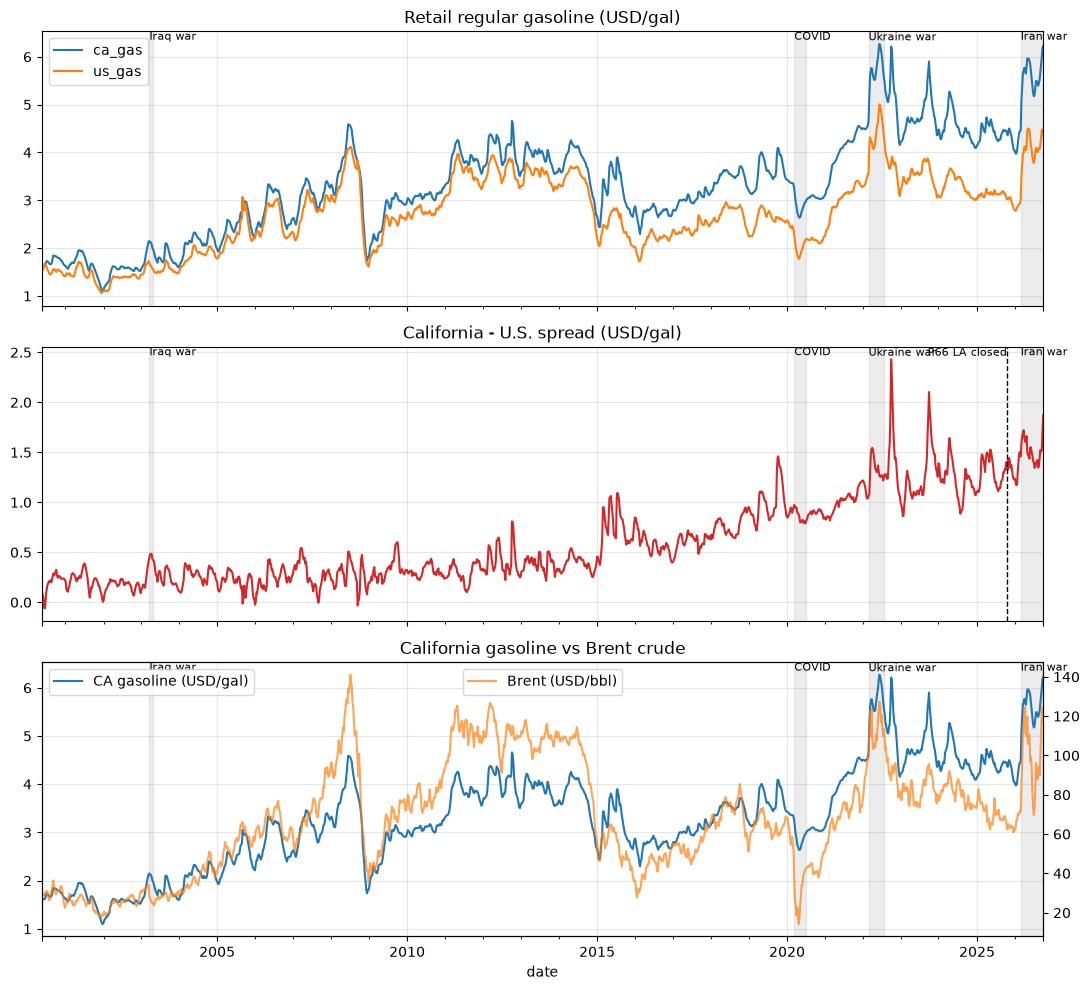

In [2]:
EVENTS = {  # shaded on the charts
    "Iraq war": ("2003-03-24", "2003-04-28"), "COVID": ("2020-03-16", "2020-06-30"),
    "Ukraine war": ("2022-02-28", "2022-07-25"), "Iran war": ("2026-03-02", df.index.max()),
}

def shade(ax):
    for name, (a, b) in EVENTS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15)
        ax.text(pd.Timestamp(a), ax.get_ylim()[1], name, fontsize=8, va="top")

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
df[["ca_gas", "us_gas"]].plot(ax=axes[0], title="Retail regular gasoline (USD/gal)")
df["spread"].plot(ax=axes[1], color="C3", title="California - U.S. spread (USD/gal)")
axes[1].axvline(pd.Timestamp("2025-10-20"), color="k", ls="--", lw=1)
axes[1].text(pd.Timestamp("2025-10-20"), axes[1].get_ylim()[1], " P66 LA closed", fontsize=8, va="top", ha="right")
ax2 = axes[2]; df["ca_gas"].plot(ax=ax2, color="C0", label="CA gasoline (USD/gal)")
ax2b = ax2.twinx(); df["brent"].plot(ax=ax2b, color="C1", alpha=0.7, label="Brent (USD/bbl)")
ax2.set_title("California gasoline vs Brent crude"); ax2b.grid(False)
ax2.legend(loc="upper left"); ax2b.legend(loc="upper center")
for ax in axes: shade(ax)
plt.tight_layout(); plt.show()

### 1.2 STL decomposition (52-week season) → summer price premium

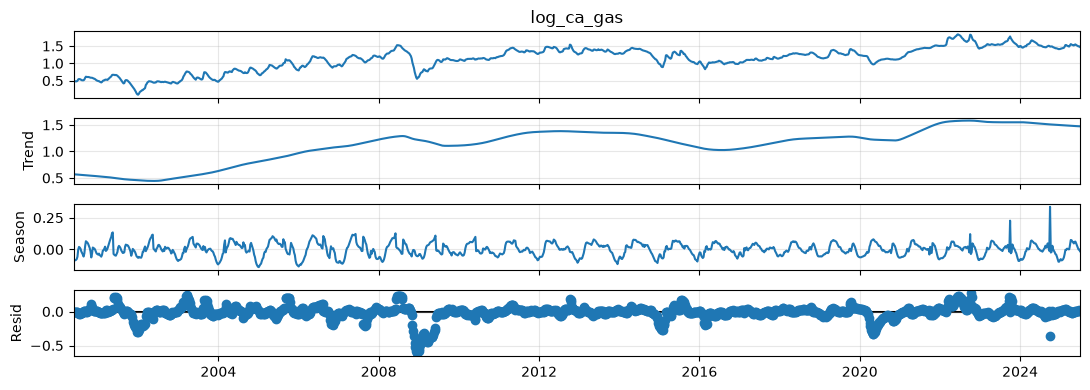

Summer (Apr-Oct) vs winter seasonal premium: 6.2%


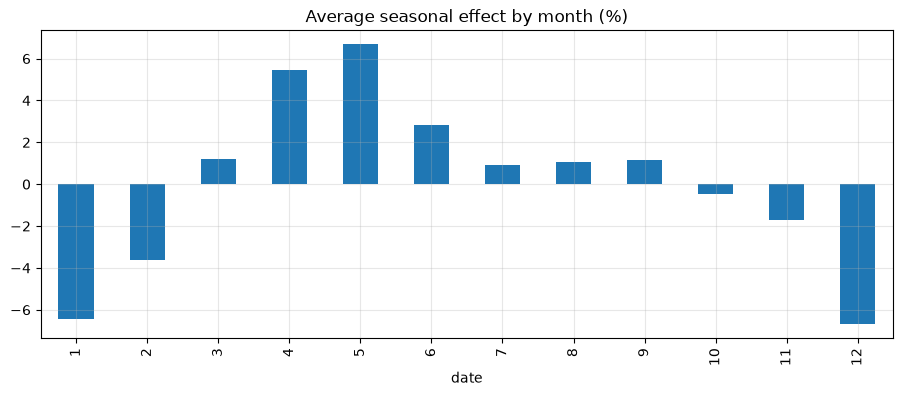

In [3]:
train = df.loc[:TRAIN_END]
stl = STL(train["log_ca_gas"], period=52, robust=True).fit()
stl.plot(); plt.show()

seas = stl.seasonal.groupby(stl.seasonal.index.month).mean()
premium = np.exp(seas.loc[4:10].mean() - seas.drop(range(4, 11)).mean()) - 1
print(f"Summer (Apr-Oct) vs winter seasonal premium: {premium:.1%}")
(np.exp(seas) - 1).mul(100).plot(kind="bar", title="Average seasonal effect by month (%)"); plt.show()

### 1.3 Unit-root tests (ADF / KPSS)
- ADF: H0 = unit root (non-stationary) → p < 0.05 means stationary
- KPSS: H0 = stationary → p < 0.05 means non-stationary

If both say "levels non-stationary, first differences stationary", we use d = 1.

In [4]:
def unit_root_table(series_dict):
    rows = []
    for name, s in series_dict.items():
        s = s.dropna()
        rows.append({"series": name,
                     "ADF p": adfuller(s, autolag="AIC")[1],
                     "KPSS p": kpss(s, regression="c", nlags="auto")[1]})
    return pd.DataFrame(rows).set_index("series").round(3)

unit_root_table({
    "log_ca_gas": train["log_ca_gas"], "diff log_ca_gas": train["log_ca_gas"].diff(),
    "log_brent": train["log_brent"], "diff log_brent": train["log_brent"].diff(),
    "spread": train["spread"],
})

,ADF p,KPSS p
series,,
log_ca_gas,0.142,0.01
diff log_ca_gas,0.000,0.10
log_brent,0.117,0.01
diff log_brent,0.000,0.10
spread,0.734,0.01


### 1.4 ACF / PACF (Δlog California price) → guide for ARIMA orders

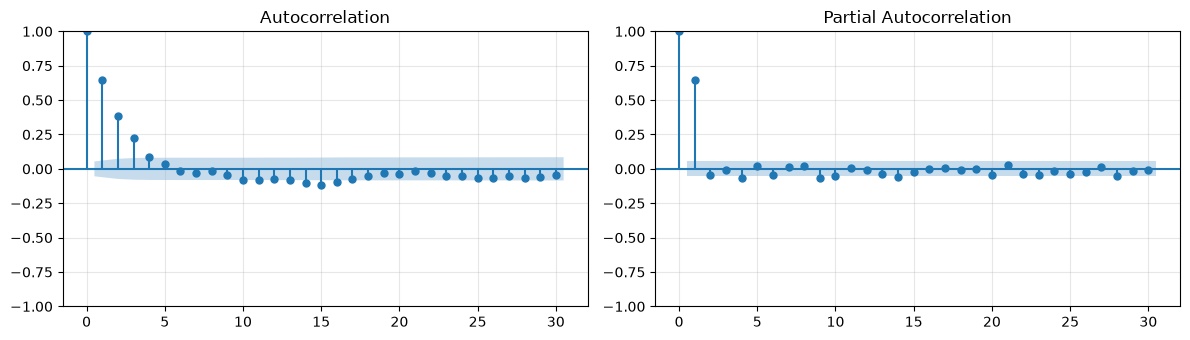

In [5]:
dy = train["log_ca_gas"].diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(dy, lags=30, ax=axes[0]); plot_pacf(dy, lags=30, ax=axes[1], method="ywm")
plt.tight_layout(); plt.show()

### 1.5 How many weeks does crude lead gasoline? (cross-correlation of weekly changes)

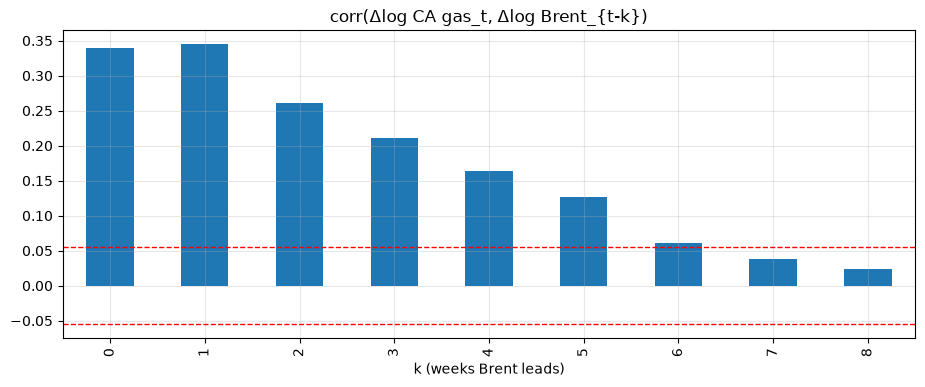

0    0.339
1    0.345
2    0.261
3    0.211
4    0.163
5    0.127
6    0.061
7    0.038
8    0.023


In [6]:
dc = train["log_brent"].diff().dropna()
dy, dc = dy.align(dc, join="inner")
# corr(dy_t, dc_{t-k}) for k = 0..8
xc = pd.Series([dy.corr(dc.shift(k)) for k in range(9)], index=range(9))
ax = xc.plot(kind="bar", title="corr(Δlog CA gas_t, Δlog Brent_{t-k})")
ax.axhline(2 / np.sqrt(len(dy)), color="r", ls="--", lw=1); ax.axhline(-2 / np.sqrt(len(dy)), color="r", ls="--", lw=1)
ax.set_xlabel("k (weeks Brent leads)"); plt.show()
print(xc.round(3).to_string())

## 2. Test design: rolling origin (expanding window)

- **Training**: 2000 – 2025-06-30; **Test**: July 2025 – latest week
- At each origin (each test week) the model is refit using only data up to that week and forecasts 1–12 weeks ahead; we score h = 4 and h = 12
- **No future information**: ARIMAX's future Brent is a random walk (= the last value observed at the origin); event dummies keep their value at the origin; only calendar dummies (summer_blend, july_tax) are known in advance

Each model only needs a `fit_forecast(train, H)` function that returns a DataFrame indexed by horizon 1..H with columns `forecast, lower80, upper80` (USD/gal); `backtest()` does the rest.

In [7]:
ORIGINS = df.loc[TRAIN_END:].index[:-1]   # last week has nothing left to score
print(f"{len(ORIGINS)} origins: {ORIGINS[0].date()} -> {ORIGINS[-1].date()}")


def backtest(name, fit_forecast, origins=ORIGINS, h=H, verbose=True):
    # Run fit_forecast at every origin and save forecasts in the shared format.
    out = []
    for i, origin in enumerate(origins):
        fc = fit_forecast(df.loc[:origin], h).copy()
        fc["horizon"] = range(1, h + 1)
        fc["origin_date"] = origin
        fc["target_date"] = origin + pd.to_timedelta(7 * fc["horizon"], unit="D")
        out.append(fc)
        if verbose and (i % 20 == 0 or i == len(origins) - 1):
            print(f"  {name}: origin {i + 1}/{len(origins)} {origin.date()}")
    out = pd.concat(out, ignore_index=True)
    out.insert(0, "model", name)
    out = out[["model", "origin_date", "horizon", "target_date", "forecast", "lower80", "upper80"]]
    out.to_csv(FC_DIR / f"{name}.csv", index=False)
    return out


def from_log(mean, sd=None, lower=None, upper=None):
    # Log-scale forecast -> USD/gal (exp of the log forecast = median).
    if sd is not None:
        lower, upper = mean - Z80 * sd, mean + Z80 * sd
    return pd.DataFrame({"forecast": np.exp(np.asarray(mean)),
                         "lower80": np.exp(np.asarray(lower)),
                         "upper80": np.exp(np.asarray(upper))}, index=range(1, len(mean) + 1))

forecasts = {}

66 origins: 2025-06-30 -> 2026-09-28


## 3. Conventional models
### 3.1 Benchmarks (every model must beat these)
- **Naive**: forecast = last week's price; 80% interval from the training-period s.d. of **h-week** changes. (The usual s.d. × √h formula assumes weekly changes are independent, but gasoline price changes are strongly autocorrelated — about 0.64 at one week — so it makes the interval far too narrow.)
- **Seasonal naive**: forecast = the price 52 weeks earlier
- **Seasonal mean (10 years)**: today's price × the average change over the same h weeks of the year in each of the previous 10 years (at least 5 needed). Simple, but a much tougher benchmark than naive because California prices have a strong seasonal pattern. Its 80% interval comes from the spread of this method's own past errors.

In [8]:
def naive_ff(train, h):
    # Weekly changes are autocorrelated, so sd * sqrt(h) is too narrow: use the actual spread of k-week changes
    y = train["log_ca_gas"]
    sd = np.array([y.diff(k).std() for k in range(1, h + 1)])
    return from_log(np.repeat(y.iloc[-1], h), sd=sd)

def snaive_ff(train, h):
    y = train["log_ca_gas"]
    sd = y.diff(52).std()
    return from_log(y.iloc[-52:-52 + h].values, sd=np.repeat(sd, h))  # target t+h <- week t+h-52

forecasts["naive"] = backtest("naive", naive_ff)
forecasts["snaive"] = backtest("snaive", snaive_ff)


def seasonal_change(y, t, k, years=10, min_years=5):
    # Average log change over weeks t..t+k at this time of year in the previous `years` years.
    # Every term ends at t - 52*yr + k <= t - 40, so only past data are used.
    terms = [y[b + k] - y[b] for yr in range(1, years + 1) if (b := t - int(round(yr * PERIOD))) >= 0]
    return np.mean(terms) if len(terms) >= min_years else np.nan

def smean_ff(train, h):
    y = train["log_ca_gas"].values
    T = len(y) - 1
    fc = np.array([seasonal_change(y, T, k) for k in range(1, h + 1)])
    # Interval: spread of the method's own errors over the last 10 years of origins whose target is observed
    sd = np.array([np.nanstd([y[t + k] - y[t] - seasonal_change(y, t, k) for t in range(T - 520, T - k + 1)])
                   for k in range(1, h + 1)])
    return from_log(y[-1] + fc, sd=sd)

forecasts["smean"] = backtest("smean", smean_ff)

  naive: origin 1/66 2025-06-30
  naive: origin 21/66 2025-11-17
  naive: origin 41/66 2026-04-06
  naive: origin 61/66 2026-08-24
  naive: origin 66/66 2026-09-28
  snaive: origin 1/66 2025-06-30
  snaive: origin 21/66 2025-11-17
  snaive: origin 41/66 2026-04-06
  snaive: origin 61/66 2026-08-24
  snaive: origin 66/66 2026-09-28


  smean: origin 1/66 2025-06-30


  smean: origin 21/66 2025-11-17


  smean: origin 41/66 2026-04-06


  smean: origin 61/66 2026-08-24


  smean: origin 66/66 2026-09-28


### 3.2 ETS (exponential smoothing)
The trend type (none / additive / damped additive) is chosen by AICc on the training set; the same specification is then refit at every origin.

In [9]:
y_train = train["log_ca_gas"]
ets_specs = {"ANN": dict(trend=None), "AAN": dict(trend="add"), "AAdN": dict(trend="add", damped_trend=True)}
ets_aicc = {k: ETSModel(y_train, error="add", **v).fit(disp=False).aicc for k, v in ets_specs.items()}
print(pd.Series(ets_aicc).round(1).to_string())
ETS_SPEC = ets_specs[min(ets_aicc, key=ets_aicc.get)]
print("Chosen:", min(ets_aicc, key=ets_aicc.get))

def ets_ff(train, h):
    y = train["log_ca_gas"]
    res = ETSModel(y, error="add", **ETS_SPEC).fit(disp=False)
    pr = res.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)
    return from_log(pr["mean"], lower=pr["pi_lower"], upper=pr["pi_upper"])

forecasts["ets"] = backtest("ets", ets_ff)

ANN    -6187.6
AAN    -6664.9
AAdN   -6841.5
Chosen: AAdN


  ets: origin 1/66 2025-06-30


  ets: origin 21/66 2025-11-17


  ets: origin 41/66 2026-04-06


  ets: origin 61/66 2026-08-24


  ets: origin 66/66 2026-09-28


### 3.3 ARIMA + Fourier terms
ARIMA(p,1,q) on log prices plus K pairs of 52-week Fourier terms (sin/cos) for seasonality — more stable than a seasonal ARIMA with period 52.

**Model selection**: on the training set, choose K by AIC using ARIMA(1,1,1), then choose p, q ∈ {0..3} by AIC. At each origin the parameters are re-estimated with the same orders (re-running automatic selection every week is slow and makes results less stable).

In [10]:
T0 = df.index[0]

def fourier(dates, K):
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD)
                         for k in range(1, K + 1) for f, fn in (("sin", np.sin), ("cos", np.cos))}, index=dates)

def fit_sarimax(y, X, order, start_params=None):
    return SARIMAX(y, exog=X, order=order, trend="n").fit(disp=False, start_params=start_params, maxiter=200)

aic_K = {K: fit_sarimax(y_train, fourier(y_train.index, K), (1, 1, 1)).aic for K in range(1, 5)}
K_BEST = min(aic_K, key=aic_K.get)
print("AIC by K:", {k: round(v, 1) for k, v in aic_K.items()}, "-> K =", K_BEST)

aic_pq = {(p, q): fit_sarimax(y_train, fourier(y_train.index, K_BEST), (p, 1, q)).aic
          for p in range(4) for q in range(4)}
p_best, q_best = min(aic_pq, key=aic_pq.get)
ORDER = (p_best, 1, q_best)
print("Chosen ARIMA order:", ORDER)

AIC by K: {1: np.float64(-6904.3), 2: np.float64(-6929.2), 3: np.float64(-6931.5), 4: np.float64(-6928.6)} -> K = 3


Chosen ARIMA order: (3, 1, 2)


In [11]:
def future_dates(train, h):
    return pd.date_range(train.index[-1] + pd.Timedelta(days=7), periods=h, freq="W-MON")

def make_arima_ff():
    state = {}
    def ff(train, h):
        y = train["log_ca_gas"]
        res = fit_sarimax(y, fourier(y.index, K_BEST), ORDER, state.get("params"))
        state["params"] = res.params
        pr = res.get_forecast(h, exog=fourier(future_dates(train, h), K_BEST)).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

forecasts["arima_fourier"] = backtest("arima_fourier", make_arima_ff())

  arima_fourier: origin 1/66 2025-06-30


  arima_fourier: origin 21/66 2025-11-17


  arima_fourier: origin 41/66 2026-04-06


  arima_fourier: origin 61/66 2026-08-24


  arima_fourier: origin 66/66 2026-09-28


### 3.4 ARIMAX: ARIMA + Fourier + Brent + event dummies

- **Brent**: lags of the *level* of `log_brent`. Because the model has d = 1 (regression with ARIMA errors; y and X are differenced together), this equals regressing Δlog gasoline on lagged Δlog Brent — the proposal's lagged weekly changes.
- **Lag 0 is allowed**: each week's Brent value is the average over the 7 days *before* that Monday, so it is already known when the Monday gasoline price is reported — no look-ahead. It is also the strongest crude predictor.
- **Which lags**: the lag set (1–4, 0–1, 0–4 or 0–8) is chosen by **BIC on the training data only**, never by test-period accuracy.
- **Future Brent**: random walk — future log Brent = its value at the origin, so ARIMAX never sees future crude prices.
- **Dummies**: `summer_blend` and `july_tax` are calendar-based, so their future values are known; other event dummies keep their origin-week value. Dummies with no variation in the training data (e.g. `p66_la_closed` before Oct 2025) are dropped automatically.

In [12]:
CAL_DUMMIES = ["summer_blend", "july_tax"]
EVENT_DUMMIES = ["covid", "iraq_war", "ukraine_war", "chevron_es_fire", "p66_la_closed", "benicia_closed", "iran_war_2026"]
BRENT_LAG_SETS = {"1-4": range(1, 5), "0-1": range(0, 2), "0-4": range(0, 5), "0-8": range(0, 9)}
BRENT_LAGS = range(1, 5)   # replaced below by the BIC choice

def calendar_dummies(dates):
    return pd.DataFrame({"summer_blend": dates.month.isin(range(4, 11)).astype(int),
                         "july_tax": ((dates.month == 7) & (dates.day <= 28)).astype(int)}, index=dates)

def arimax_exog(train, h):
    # Exog for the training sample and for the h future weeks, using only info known at the origin.
    fut = future_dates(train, h)
    lb = pd.concat([train["log_brent"], pd.Series(train["log_brent"].iloc[-1], index=fut)])  # random walk
    lags = pd.DataFrame({f"log_brent_l{k}": lb.shift(k) for k in BRENT_LAGS})
    events = [c for c in EVENT_DUMMIES if train[c].nunique() > 1]
    ev = pd.concat([train[events], pd.DataFrame([train[events].iloc[-1].values] * h, index=fut, columns=events)])
    idx = lags.index
    X = pd.concat([fourier(idx, K_BEST), lags, calendar_dummies(idx), ev], axis=1).iloc[max(BRENT_LAGS):]
    return X.loc[:train.index[-1]], X.loc[fut]

def make_arimax_ff():
    state = {}
    def ff(train, h):
        X, Xf = arimax_exog(train, h)
        y = train["log_ca_gas"].loc[X.index]
        key = tuple(X.columns)  # dummies enter the model over time -> reuse params only if same columns
        res = fit_sarimax(y, X, ORDER, state.get(key))
        state[key] = res.params
        pr = res.get_forecast(h, exog=Xf).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

# Choose the Brent lag set by BIC on the training data (same estimation sample for every set)
ic = {}
for name, lags in BRENT_LAG_SETS.items():
    BRENT_LAGS = lags
    X_tr, _ = arimax_exog(train, 1)
    X_tr = X_tr.loc[train.index[8]:]
    r = fit_sarimax(train["log_ca_gas"].loc[X_tr.index], X_tr, ORDER)
    ic[name] = {"AIC": r.aic, "BIC": r.bic}
ic = pd.DataFrame(ic).T.round(1)
BRENT_LAGS = BRENT_LAG_SETS[ic["BIC"].idxmin()]
print(ic.to_string(), f"\n-> Brent lags {ic['BIC'].idxmin()} (lowest BIC)")

forecasts["arimax"] = backtest("arimax", make_arimax_ff())

# Coefficients on the full training sample
X_tr, _ = arimax_exog(train, 1)
arimax_train = fit_sarimax(train["log_ca_gas"].loc[X_tr.index], X_tr, ORDER)
arimax_train.summary().tables[1]

        AIC     BIC
1-4 -6938.0 -6829.4
0-1 -7027.3 -6929.0
0-4 -7093.9 -6980.1
0-8 -7117.0 -6982.5 
-> Brent lags 0-8 (lowest BIC)


  arimax: origin 1/66 2025-06-30


  arimax: origin 21/66 2025-11-17


  arimax: origin 41/66 2026-04-06


  arimax: origin 61/66 2026-08-24


  arimax: origin 66/66 2026-09-28


,coef,std err,z,P>|z|,[0.025,0.975]
sin1,0.0215,0.009,2.359,0.018,0.004,0.039
cos1,0.0508,0.007,6.922,0.000,0.036,0.065
sin2,-0.0283,0.006,-4.898,0.000,-0.040,-0.017
cos2,0.0094,0.006,1.680,0.093,-0.002,0.020
sin3,0.0060,0.004,1.437,0.151,-0.002,0.014
cos3,0.0017,0.004,0.445,0.656,-0.006,0.009
log_brent_l0,0.1192,0.009,13.629,0.000,0.102,0.136
log_brent_l1,0.1125,0.010,11.115,0.000,0.093,0.132
log_brent_l2,0.0727,0.010,7.457,0.000,0.054,0.092
log_brent_l3,0.0557,0.009,6.491,0.000,0.039,0.073


### 3.5 AI models (precomputed forecasts)
The AI models need PyTorch, so they run in a separate environment and save CSVs in the same format as the other models:
- `ai_models.py`: **Chronos-Bolt**, **Chronos-2** (Amazon) and **TimesFM 2.5** (Google), zero-shot (no retraining), using the last 512 weeks as context at each origin
- `llm/llm_experiments.py`: **Claude** and **ChatGPT**, every 4th test week with 3 repeats averaged, in two experiments: anonymized (anon) and full context (context)

This cell loads the AI forecasts from `forecasts/`; the evaluation, DM tests and combination below then include them automatically.

In [13]:
AI_PREFIXES = ("chronos", "timesfm", "llm_")
is_ai = lambda m: m.startswith(AI_PREFIXES)
for f in sorted(FC_DIR.glob("*.csv")):
    if is_ai(f.stem):
        forecasts[f.stem] = pd.read_csv(f, parse_dates=["origin_date", "target_date"])
print("AI forecasts loaded:", [m for m in forecasts if is_ai(m)] or "none (run ai_models.py first)")

ai_log = RES_DIR / "ai_model_log.csv"
pd.read_csv(ai_log) if ai_log.exists() else None

AI forecasts loaded: ['chronos2', 'chronos_bolt', 'timesfm']


,model,repo,revision,released,release_inside_test_period,context_weeks,run_at,runtime_s
0,chronos_bolt,amazon/chronos-bolt-small,772f3d25d3,2024-11-25,False,512,2026-10-13 14:14,11
1,chronos2,amazon/chronos-2,29ec3766d3,2025-10-30,True,512,2026-10-13 14:15,19
2,timesfm,google/timesfm-2.5-200m-pytorch,1d952420fb,2025-09-02,True,512,2026-10-13 14:15,40


## 4. Evaluation
- **MAE / RMSE / MAPE** (USD/gal) at h = 4, 12
- **Skill vs naive** = MAE / naive MAE (< 1 means the model beats naive)
- **Coverage80** = share of actual prices inside the 80% interval (ideal ≈ 0.80)
- **DirAcc** = % of forecasts that got the *direction* of the price change right (up or down vs the origin week). Forecasts of no change (naive) are left out, so naive has no DirAcc; a coin flip scores about 50%
- **Forecast combination**: as designed in the proposal, the average of the best conventional and the best AI model — tests whether AI adds information the conventional models lack
- The LLMs forecast only every 4th week, so their `n` is smaller; section 7 compares them fairly (only on the weeks the LLMs forecast)

In [14]:
def evaluate(fc_dict):
    all_fc = pd.concat(fc_dict.values(), ignore_index=True)
    all_fc["actual"] = all_fc["target_date"].map(df["ca_gas"])
    all_fc = all_fc.dropna(subset=["actual"])
    all_fc["err"] = all_fc["actual"] - all_fc["forecast"]
    all_fc["covered"] = all_fc["actual"].between(all_fc["lower80"], all_fc["upper80"])
    origin_price = all_fc["origin_date"].map(df["ca_gas"])
    f_move, a_move = all_fc["forecast"] - origin_price, all_fc["actual"] - origin_price
    f_dir = np.where(f_move.abs() < 1e-6, 0, np.sign(f_move))       # "no change" forecasts don't count
    all_fc["dir_ok"] = np.where(f_dir == 0, np.nan, (f_dir == np.sign(a_move)).astype(float))
    sc = all_fc[all_fc["horizon"].isin(SCORE_H)].assign(
        abs_err=lambda d: d.err.abs(), sq_err=lambda d: d.err ** 2, ape=lambda d: (d.err / d.actual).abs() * 100)
    m = sc.groupby(["horizon", "model"]).agg(
        n=("err", "size"), MAE=("abs_err", "mean"), RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
        MAPE=("ape", "mean"), Coverage80=("covered", "mean"), DirAcc=("dir_ok", lambda s: s.mean() * 100))
    naive_mae = m["MAE"].xs("naive", level="model")
    m["Skill_vs_naive"] = m["MAE"] / naive_mae.reindex(m.index.get_level_values("horizon")).values
    return all_fc, m.round(3)

all_fc, metrics = evaluate(forecasts)
metrics.sort_values(["horizon", "MAE"])

n    MAE   RMSE    MAPE  Coverage80  DirAcc  \
horizon model                                                         
4       arima_fourier  63  0.218  0.312   4.112       0.810  71.429   
        arimax         63  0.223  0.331   4.210       0.714  74.603   
        smean          63  0.236  0.311   4.601       0.794  63.492   
        timesfm        63  0.256  0.361   4.909       0.746  63.492   
        naive          63  0.270  0.384   5.233       0.794     NaN   
        chronos2       63  0.273  0.384   5.205       0.730  58.730   
        chronos_bolt   63  0.277  0.384   5.308       0.683  55.556   
        ets            63  0.281  0.378   5.374       0.841  63.492   
        snaive         63  0.631  0.848  11.421       0.841  57.143   
12      arima_fourier  55  0.410  0.581   7.526       0.745  80.000   
        smean          55  0.437  0.619   7.883       0.764  81.818   
        arimax         55  0.503  0.681   9.190       0.636  70.909   
        chronos2       55  0.575  0.818  10.566       0.673  56.364   
        chronos_bolt   55  0.579  0.829  10.592       0.691  56.364   
        timesfm        55  0.582  0.820  10.697       0.709  54.545   
        naive          55  0.600  0.812  11.109       0.782     NaN   
        snaive         55  0.715  0.907  12.895       0.818  81.818   
        ets            55  0.725  0.904  13.502       0.836  41.818   

                       Skill_vs_naive  
horizon model                          
4       arima_fourier           0.806  
        arimax                  0.826  
        smean                   0.871  
        timesfm                 0.948  
        naive                   1.000  
        chronos2                1.009  
        chronos_bolt            1.025  
        ets                     1.039  
        snaive                  2.335  
12      arima_fourier           0.683  
        smean                   0.728  
        arimax                  0.839  
        chronos2                0.959  
        chronos_bolt            0.966  
        timesfm                 0.970  
        naive                   1.000  
        snaive                  1.192  
        ets                     1.208

In [15]:
# Forecast combination: best conventional + best AI model (by h = 4 MAE). Only models that forecast at
# every origin are eligible, so the LLMs (every 4th week) are left out of the combination.
m4 = metrics.xs(4, level="horizon")
full = m4[m4["n"] == m4.loc["naive", "n"]].index
conventional = [m for m in full if not is_ai(m) and m not in ("naive", "snaive", "smean", "combo")]
ai_full = [m for m in full if is_ai(m)]
best_conv = m4.loc[conventional, "MAE"].idxmin()
COMBO = [best_conv, m4.loc[ai_full, "MAE"].idxmin()] if ai_full else list(m4.loc[conventional, "MAE"].nsmallest(2).index)
combo = (pd.concat([forecasts[m] for m in COMBO])
         .groupby(["origin_date", "horizon", "target_date"], as_index=False)[["forecast", "lower80", "upper80"]].mean())
combo.insert(0, "model", "combo")
combo.to_csv(FC_DIR / "combo.csv", index=False)
forecasts["combo"] = combo
print("Combination of:", COMBO)

all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.sort_values(["horizon", "MAE"])

Combination of: ['arima_fourier', 'timesfm']


n    MAE   RMSE    MAPE  Coverage80  DirAcc  \
horizon model                                                         
4       arima_fourier  63  0.218  0.312   4.112       0.810  71.429   
        arimax         63  0.223  0.331   4.210       0.714  74.603   
        combo          63  0.227  0.328   4.312       0.825  71.429   
        smean          63  0.236  0.311   4.601       0.794  63.492   
        timesfm        63  0.256  0.361   4.909       0.746  63.492   
        naive          63  0.270  0.384   5.233       0.794     NaN   
        chronos2       63  0.273  0.384   5.205       0.730  58.730   
        chronos_bolt   63  0.277  0.384   5.308       0.683  55.556   
        ets            63  0.281  0.378   5.374       0.841  63.492   
        snaive         63  0.631  0.848  11.421       0.841  57.143   
12      arima_fourier  55  0.410  0.581   7.526       0.745  80.000   
        smean          55  0.437  0.619   7.883       0.764  81.818   
        combo          55  0.469  0.690   8.512       0.727  70.909   
        arimax         55  0.503  0.681   9.190       0.636  70.909   
        chronos2       55  0.575  0.818  10.566       0.673  56.364   
        chronos_bolt   55  0.579  0.829  10.592       0.691  56.364   
        timesfm        55  0.582  0.820  10.697       0.709  54.545   
        naive          55  0.600  0.812  11.109       0.782     NaN   
        snaive         55  0.715  0.907  12.895       0.818  81.818   
        ets            55  0.725  0.904  13.502       0.836  41.818   

                       Skill_vs_naive  
horizon model                          
4       arima_fourier           0.806  
        arimax                  0.826  
        combo                   0.841  
        smean                   0.871  
        timesfm                 0.948  
        naive                   1.000  
        chronos2                1.009  
        chronos_bolt            1.025  
        ets                     1.039  
        snaive                  2.335  
12      arima_fourier           0.683  
        smean                   0.728  
        combo                   0.783  
        arimax                  0.839  
        chronos2                0.959  
        chronos_bolt            0.966  
        timesfm                 0.970  
        naive                   1.000  
        snaive                  1.192  
        ets                     1.208

### 4.1 Diebold-Mariano test
H0: both models are equally accurate (squared-error loss). HAC variance with h−1 lags plus the Harvey-Leybourne-Newbold small-sample correction. DM < 0 means the first model is more accurate. Each pair is compared only on the dates both models forecast.

In [16]:
def dm_test(e1, e2, h, power=2):
    d = np.abs(e1) ** power - np.abs(e2) ** power
    n, dbar = len(d), d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:  # HAC estimate can turn negative for long horizons -> fall back to plain variance
        var = gamma[0] / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

rows = []
for h in SCORE_H:
    e = all_fc[all_fc.horizon == h].pivot(index="origin_date", columns="model", values="err")
    for m in e.columns:
        for bench in ["naive", best_conv]:
            if m != bench:
                pair = e[[m, bench]].dropna()   # align each pair on the dates both models forecast
                dm, p = dm_test(pair[m].values, pair[bench].values, h)
                rows.append({"horizon": h, "model": m, "vs": bench, "n": len(pair), "DM": dm, "p": p})
dm_table = pd.DataFrame(rows).round(3)
dm_table.to_csv(RES_DIR / "dm_tests.csv", index=False)
print("Best conventional model (h=4 MAE):", best_conv)
dm_table

Best conventional model (h=4 MAE): arima_fourier


,horizon,model,vs,n,DM,p
0,4,arima_fourier,naive,63,-1.431,0.157
1,4,arimax,naive,63,-0.917,0.363
2,4,arimax,arima_fourier,63,0.891,0.376
3,4,chronos2,naive,63,-0.014,0.989
4,4,chronos2,arima_fourier,63,1.905,0.061
5,4,chronos_bolt,naive,63,-0.025,0.980
6,4,chronos_bolt,arima_fourier,63,2.214,0.031
7,4,combo,naive,63,-1.413,0.163
8,4,combo,arima_fourier,63,1.377,0.174
9,4,ets,naive,63,-0.180,0.858


### 4.2 Forecasts vs actual

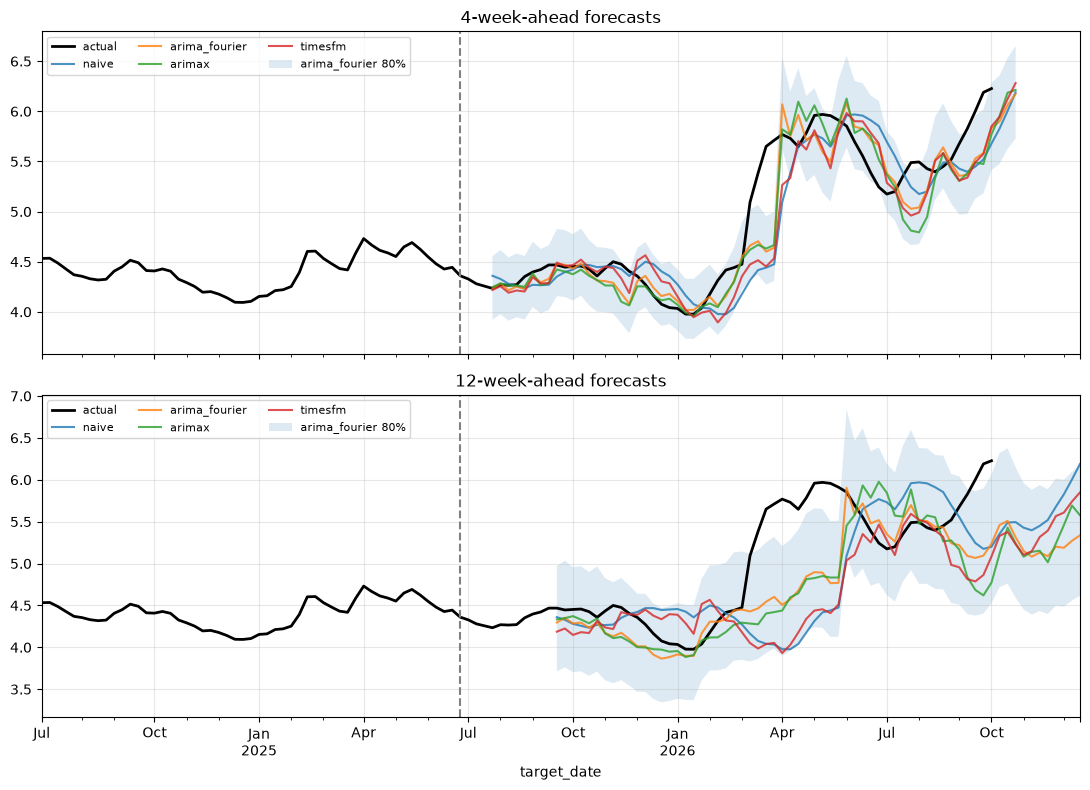

In [17]:
fig, axes = plt.subplots(len(SCORE_H), 1, figsize=(11, 8), sharex=True)
for ax, h in zip(axes, SCORE_H):
    df.loc["2024-07":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
    for m in ["naive", "arima_fourier", "arimax"] + (COMBO[1:] if ai_full else []):
        f = forecasts[m].query("horizon == @h").set_index("target_date")
        f["forecast"].plot(ax=ax, label=m, alpha=0.8)
    f = forecasts[best_conv].query("horizon == @h").set_index("target_date")
    ax.fill_between(f.index, f["lower80"], f["upper80"], alpha=0.15, label=f"{best_conv} 80%")
    ax.axvline(pd.Timestamp(TRAIN_END), color="grey", ls="--")
    ax.set_title(f"{h}-week-ahead forecasts"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

### 4.3 How much of ARIMAX's error comes from not knowing future crude?
A diagnostic, not a real forecast: rerun ARIMAX but give it the **actual** future Brent prices instead of holding Brent flat. No forecaster has this information, so it is an upper bound on what a perfect crude forecast could add. The gap between the two shows how much of ARIMAX's error is crude uncertainty versus everything else. The oracle forecasts are kept out of `forecasts/` so they never enter the model rankings.

In [18]:
def make_arimax_oracle_ff():
    state, lb_all = {}, df["log_brent"]
    def ff(train, h):
        X, Xf = arimax_exog(train, h)
        for k in BRENT_LAGS:   # replace the flat-Brent assumption with the realised Brent path
            Xf[f"log_brent_l{k}"] = lb_all.shift(k).reindex(Xf.index).fillna(lb_all.iloc[-1]).values
        key = tuple(X.columns)
        res = fit_sarimax(train["log_ca_gas"].loc[X.index], X, ORDER, state.get(key))
        state[key] = res.params
        pr = res.get_forecast(h, exog=Xf).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

oracle_fc = backtest("arimax_oracle", make_arimax_oracle_ff(), verbose=False)
(FC_DIR / "arimax_oracle.csv").replace(RES_DIR / "arimax_oracle_forecasts.csv")   # keep out of the rankings

_, om = evaluate({"arimax": forecasts["arimax"], "arimax_oracle": oracle_fc, "naive": forecasts["naive"]})
oracle_tab = om["MAE"].unstack("model")[["arimax", "arimax_oracle"]]
oracle_tab["best_conventional"] = metrics["MAE"].xs(best_conv, level="model")
oracle_tab["share_of_ARIMAX_error_from_crude"] = 1 - oracle_tab["arimax_oracle"] / oracle_tab["arimax"]
oracle_tab = oracle_tab.round(3)
oracle_tab.to_csv(RES_DIR / "oracle_crude.csv")
for h, r in oracle_tab.iterrows():
    print(f"h={h}: ARIMAX MAE {r.arimax:.3f} -> {r.arimax_oracle:.3f} with the real crude path "
          f"({r.share_of_ARIMAX_error_from_crude:.0%} of its error is crude uncertainty)")
oracle_tab

h=4: ARIMAX MAE 0.223 -> 0.177 with the real crude path (21% of its error is crude uncertainty)
h=12: ARIMAX MAE 0.503 -> 0.282 with the real crude path (44% of its error is crude uncertainty)


model,arimax,arimax_oracle,best_conventional,share_of_ARIMAX_error_from_crude
horizon,,,,
4,0.223,0.177,0.218,0.206
12,0.503,0.282,0.410,0.439


## 5. VAR, Granger causality, impulse response
Δlog Brent and Δlog California price over the training period, lag order chosen by AIC. The impulse response uses a Cholesky ordering (Brent first) and is scaled to the cumulative response of California gasoline to a **10% rise in Brent**.

Lag order (AIC): 10
d_brent Granger-causes d_ca_gas?  F = 6.29, p = 0.0000
d_ca_gas Granger-causes d_brent?  F = 1.32, p = 0.2130


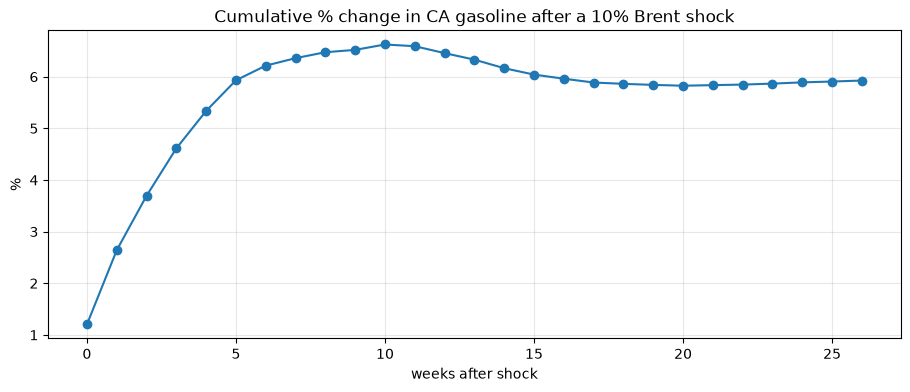

After 4 weeks: 5.34%, after 12 weeks: 6.46%, after 26 weeks: 5.93%


In [19]:
var_data = train[["log_brent", "log_ca_gas"]].diff().dropna()
var_data.columns = ["d_brent", "d_ca_gas"]
var_res = VAR(var_data).fit(maxlags=12, ic="aic")
print("Lag order (AIC):", var_res.k_ar)

for caused, causing in [("d_ca_gas", "d_brent"), ("d_brent", "d_ca_gas")]:
    t = var_res.test_causality(caused, [causing], kind="f")
    print(f"{causing} Granger-causes {caused}?  F = {t.test_statistic:.2f}, p = {t.pvalue:.4f}")

irf = var_res.irf(26)
oi = irf.orth_irfs  # [step, response, shock]
b, c = 0, 1         # column positions: d_brent, d_ca_gas
pass_through = pd.Series(np.cumsum(oi[:, c, b]) / oi[0, b, b] * 0.10, name="cum. response")
ax = (pass_through * 100).plot(marker="o", title="Cumulative % change in CA gasoline after a 10% Brent shock")
ax.set_xlabel("weeks after shock"); ax.set_ylabel("%"); plt.show()
print(f"After 4 weeks: {pass_through[4]:.2%}, after 12 weeks: {pass_through[12]:.2%}, after 26 weeks: {pass_through[26]:.2%}")

## 6. Rockets and feathers: asymmetric error-correction model

$$\Delta P_t = \alpha + \sum_{i=0}^{k} \beta_i^{+} \Delta C_{t-i}^{+} + \sum_{i=0}^{k} \beta_i^{-} \Delta C_{t-i}^{-} + \gamma (P_{t-1} - \theta C_{t-1}) + \varepsilon_t$$

- P = California gasoline price (USD/gal), C = Brent (converted to USD/gal = USD/bbl ÷ 42)
- **Long-run equation with a time trend**: $P_t = a + \theta C_t + \delta t$. Without the trend, gasoline and crude are not cointegrated (Engle-Granger test below), so the error-correction term would be meaningless. The trend captures steadily rising non-crude costs (taxes, California-specific costs).
- Engle-Granger two-step: estimate the long-run equation, then the ECM with HAC standard errors
- **Asymmetry is about speed as well as size.** Wald tests of H0: increases = decreases for the same-week effect, the cumulative effect through 1 week, the total effect, and every lag jointly. "Rockets and feathers" means increases pass through faster even if the total effect ends up the same.

In [20]:
from statsmodels.tsa.stattools import coint

K_ECM = 4
P, C = train["ca_gas"], train["brent"] / 42
trend = pd.Series(np.arange(len(C)), index=C.index, name="trend")

for tr, label in [("c", "constant only"), ("ct", "constant + time trend")]:
    print(f"Engle-Granger cointegration test, {label:22s}: p = {coint(P, C, trend=tr)[1]:.3f}")

lr = sm.OLS(P, sm.add_constant(pd.concat([C, trend], axis=1))).fit()
theta, ect = lr.params["brent"], lr.resid

dC = C.diff()
ecm = pd.DataFrame({"dP": P.diff(), "ect_l1": ect.shift(1)})
for i in range(K_ECM + 1):
    ecm[f"dCpos_l{i}"] = dC.clip(lower=0).shift(i)
    ecm[f"dCneg_l{i}"] = dC.clip(upper=0).shift(i)
ecm = ecm.dropna()
ecm_res = sm.OLS(ecm["dP"], sm.add_constant(ecm.drop(columns="dP"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
gamma = ecm_res.params["ect_l1"]
print(f"\nLong run: theta = {theta:.3f} USD/gal per USD/gal of crude, trend = {lr.params['trend'] * 52:+.3f} USD/gal per year")
print(f"Error correction: gamma = {gamma:.4f} (p = {ecm_res.pvalues['ect_l1']:.3f}), "
      f"half-life of a deviation = {np.log(0.5) / np.log(1 + gamma):.0f} weeks\n")
print(ecm_res.summary().tables[1])

pos = [f"dCpos_l{i}" for i in range(K_ECM + 1)]; neg = [f"dCneg_l{i}" for i in range(K_ECM + 1)]
names = list(ecm_res.params.index)

def wald_p(rows):
    # rows: list of (increase terms, decrease terms); H0: sum(increase) = sum(decrease) for every row
    R = np.zeros((len(rows), len(names)))
    for r, (up, down) in enumerate(rows):
        for v in up: R[r, names.index(v)] += 1
        for v in down: R[r, names.index(v)] -= 1
    return float(ecm_res.wald_test(R, scalar=True).pvalue)

tests = [{"test": label, "increase": ecm_res.params[pos[:j + 1]].sum(), "decrease": ecm_res.params[neg[:j + 1]].sum(),
          "p-value": wald_p([(pos[:j + 1], neg[:j + 1])])}
         for j, label in [(0, "same week (lag 0)"), (1, "cumulative through lag 1"), (K_ECM, f"total (lags 0-{K_ECM})")]]
tests.append({"test": "every lag equal (joint)", "increase": np.nan, "decrease": np.nan,
              "p-value": wald_p([([u], [d]) for u, d in zip(pos, neg)])})
asym = pd.DataFrame(tests).set_index("test").round(3)

first, total = asym.iloc[0], asym.iloc[2]
level = "5%" if first["p-value"] < 0.05 else "10%" if first["p-value"] < 0.10 else None
print(f"\nSame week: increases pass through {first['increase']:.2f} vs decreases {first['decrease']:.2f} "
      + (f"(p = {first['p-value']:.3f}, significant at {level})" if level else f"(p = {first['p-value']:.3f}, not significant)"))
print(f"Total: {total['increase']:.2f} vs {total['decrease']:.2f} (p = {total['p-value']:.3f})"
      + (" -> decreases catch up; the total effect is the same" if total["p-value"] >= 0.10 else ""))
asym

Engle-Granger cointegration test, constant only         : p = 0.891
Engle-Granger cointegration test, constant + time trend : p = 0.001

Long run: theta = 0.874 USD/gal per USD/gal of crude, trend = +0.077 USD/gal per year
Error correction: gamma = -0.0231 (p = 0.073), half-life of a deviation = 30 weeks



                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0009      0.004     -0.212      0.832      -0.010       0.008
ect_l1        -0.0231      0.013     -1.792      0.073      -0.048       0.002
dCpos_l0       0.4890      0.088      5.542      0.000       0.316       0.662
dCneg_l0       0.2454      0.058      4.232      0.000       0.132       0.359
dCpos_l1       0.3049      0.063      4.825      0.000       0.181       0.429
dCneg_l1       0.2637      0.037      7.131      0.000       0.191       0.336
dCpos_l2       0.1573      0.048      3.249      0.001       0.062       0.252
dCneg_l2       0.2407      0.048      5.001      0.000       0.146       0.335
dCpos_l3       0.0982      0.058      1.680      0.093      -0.016       0.213
dCneg_l3       0.1048      0.063      1.669      0.095      -0.018       0.228
dCpos_l4       0.0475      0.049      0.974      0.3

,increase,decrease,p-value
test,,,
same week (lag 0),0.489,0.245,0.064
cumulative through lag 1,0.794,0.509,0.096
total (lags 0-4),1.097,1.007,0.593
every lag equal (joint),NaN,NaN,0.394


## 7. AI vs conventional models (research question 3)

### 7.1 Time-series foundation models
Chronos-Bolt, Chronos-2 and TimesFM 2.5 are all zero-shot: they are not retrained on California gasoline; they only receive the last 512 weeks of prices as input.

**Look-ahead check**: a model's release date is an upper bound on its training data. Models released during the test period (July 2025 onward) could in principle have seen part of the test data; Chronos-Bolt (Nov 2024) was released before the test period, so it is the cleanest comparison.

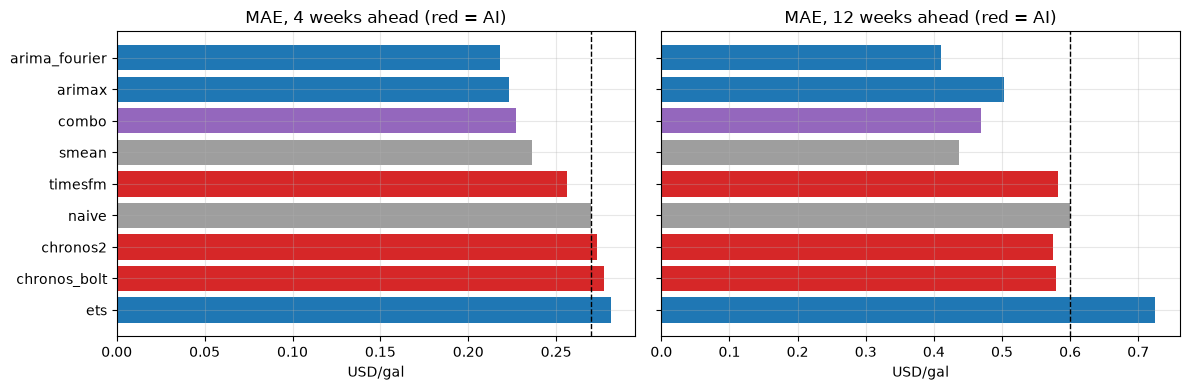

,horizon,model,type,MAE,Skill_vs_naive,Coverage80
0,4,arima_fourier,Conventional,0.218,0.806,0.810
1,4,arimax,Conventional,0.223,0.826,0.714
4,4,combo,Combination,0.227,0.841,0.825
7,4,smean,Benchmark,0.236,0.871,0.794
8,4,timesfm,AI,0.256,0.948,0.746
6,4,naive,Benchmark,0.270,1.000,0.794
2,4,chronos2,AI,0.273,1.009,0.730
3,4,chronos_bolt,AI,0.277,1.025,0.683
5,4,ets,Conventional,0.281,1.039,0.841
9,12,arima_fourier,Conventional,0.410,0.683,0.745


In [21]:
rows = []
for h in SCORE_H:
    mh = metrics.xs(h, level="horizon")
    for m in mh.index:
        if m == "snaive" or m.startswith("llm_"):
            continue
        kind = ("AI" if is_ai(m) else "Benchmark" if m in ("naive", "smean") else
                "Combination" if m == "combo" else "Conventional")
        rows.append({"horizon": h, "model": m, "type": kind,
                     "MAE": mh.loc[m, "MAE"], "Skill_vs_naive": mh.loc[m, "Skill_vs_naive"], "Coverage80": mh.loc[m, "Coverage80"]})
ai_vs = pd.DataFrame(rows).sort_values(["horizon", "MAE"])

fig, axes = plt.subplots(1, len(SCORE_H), figsize=(12, 4), sharey=True)
colors = {"AI": "#d62728", "Conventional": "#1f77b4", "Benchmark": "#9e9e9e", "Combination": "#9467bd"}
for ax, h in zip(axes, SCORE_H):
    d = ai_vs[ai_vs.horizon == h].sort_values("MAE", ascending=False)
    ax.barh(d["model"], d["MAE"], color=d["type"].map(colors))
    ax.axvline(d.loc[d.model == "naive", "MAE"].iloc[0], color="k", ls="--", lw=1)
    ax.set_title(f"MAE, {h} weeks ahead (red = AI)"); ax.set_xlabel("USD/gal")
plt.tight_layout(); plt.show()
ai_vs.round(3)

### 7.2 LLM experiments (Claude, ChatGPT)
- **Experiment 1 (anon)**: the LLM sees only the last 156 weekly values rescaled to an index (first week = 100) — no series name, no dates
- **Experiment 2 (context)**: the LLM is told it is California gasoline and gets dates, recent Brent prices, and a news summary of events **known on the forecast date**
- The gap between the two = how much of the LLM's accuracy comes from background knowledge rather than pattern recognition

The LLMs run on only 17 forecast dates (every 4th week), so here **all models are compared on those 17 dates only**, for fairness. Every prompt, model version and raw response is logged in `results/llm_log.jsonl`.

In [22]:
llm_models = [m for m in forecasts if m.startswith("llm_")]
if not llm_models:
    print("No LLM forecasts yet. Set ANTHROPIC_API_KEY / OPENAI_API_KEY and run:\n"
          "  .venv-ai/bin/python llm/llm_experiments.py")
else:
    llm_dates = set(forecasts[llm_models[0]]["origin_date"])
    same = all_fc[all_fc["origin_date"].isin(llm_dates) & all_fc["horizon"].isin(SCORE_H)]
    keep = llm_models + ["naive", best_conv] + ai_full
    llm_table = (same[same.model.isin(keep)].assign(ae=lambda d: d.err.abs())
                 .pivot_table(index="model", columns="horizon", values="ae", aggfunc="mean").round(3)
                 .sort_values(SCORE_H[0]))
    llm_table.columns = [f"MAE h={h}" for h in llm_table.columns]
    print(f"MAE on the {len(llm_dates)} LLM forecast dates only")
    display(llm_table)
    for prov in sorted({m.split("_")[1] for m in llm_models}):
        a, c = f"llm_{prov}_anon", f"llm_{prov}_context"
        if a in llm_table.index and c in llm_table.index:
            gap = llm_table.loc[a] - llm_table.loc[c]
            print(f"{prov}: anon - context MAE = " + ", ".join(f"{k}: {v:+.3f}" for k, v in gap.items())
                  + "  (positive = background knowledge helps)")

No LLM forecasts yet. Set ANTHROPIC_API_KEY / OPENAI_API_KEY and run:
  .venv-ai/bin/python llm/llm_experiments.py


## 8. Scenario forecasts: with vs without events

Run the same model twice: once assuming **no new event** (baseline) and once assuming **an event happens**; the gap between the two forecasts is the event's effect.

**Model (ARDL in weekly changes)**

$$\Delta \log P_t = c + \sum_{i=1}^{4}\phi_i \Delta \log P_{t-i} + \sum_{k=0}^{8}\beta_k \Delta \log \text{Brent}_{t-k} + \text{seasonal terms} + \delta_1 \text{Spike}_t + \delta_2 \text{Recovery}_t + \varepsilon_t$$

| Event | How it enters the model | Evidence |
|---|---|---|
| **War / ceasefire** | Change the future **Brent path** | History: once Brent is controlled for, prices rose no extra during wars — the effect runs through crude |
| **Unplanned refinery outage** (fire, explosion, power loss) | **Spike** (weeks 1–3 = 1) + **Recovery** (weeks 4–8 = 1) | Estimated from 4 past outages: prices jump, then partly fall back |
| Planned refinery closure | Not included by default | No jump at the Phillips 66 or Benicia closures (announced a year ahead, so markets had already adjusted) |

**Why not ARIMAX for scenarios?** In ARIMAX a crude change affects gasoline only through its few Brent lags and does not build up over time, so it understates crude's effect. This model includes gasoline's own lags, so Brent and outage shocks keep passing through over time, which suits scenario analysis. Intervals come from 1,000 paths simulated by bootstrapping the residuals.

In [23]:
OUTAGES = {  # unplanned California refinery outages (first Monday on/after the event)
    "Chevron Richmond fire": "2012-08-06",
    "ExxonMobil Torrance power outage": "2012-10-01",
    "ExxonMobil Torrance explosion": "2015-02-23",
    "Chevron El Segundo fire": "2025-10-06",
}
SPIKE_W, RECOV_W = 3, 5     # weeks 1-3 prices jump, weeks 4-8 partly reverse
P_AR, Q_BRENT = 4, 8

def outage_dummies(index, starts):
    spike = pd.Series(0.0, index=index, name="outage_spike")
    rec = pd.Series(0.0, index=index, name="outage_recovery")
    for d in map(pd.Timestamp, starts):
        if d in index:
            i = index.get_loc(d)
            spike.iloc[i:i + SPIKE_W] = 1
            rec.iloc[i + SPIKE_W:i + SPIKE_W + RECOV_W] = 1
    return spike, rec

def seas_diff(dates):
    # First difference of the Fourier terms (the model is in weekly changes)
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD) - fn(2 * np.pi * k * (t - 1) / PERIOD)
                         for k in range(1, K_BEST + 1) for f, fn in (("ds", np.sin), ("dc", np.cos))}, index=dates)

def fit_ardl(data):
    dy, db = data["log_ca_gas"].diff(), data["log_brent"].diff()
    spike, rec = outage_dummies(data.index, OUTAGES.values())
    X = pd.concat([pd.DataFrame({f"dy_l{i}": dy.shift(i) for i in range(1, P_AR + 1)}),
                   pd.DataFrame({f"db_l{k}": db.shift(k) for k in range(Q_BRENT + 1)}),
                   seas_diff(data.index), spike, rec], axis=1)
    d = pd.concat([dy.rename("dy"), sm.add_constant(X)], axis=1).dropna()
    return sm.OLS(d["dy"], d.drop(columns="dy")).fit(cov_type="HAC", cov_kwds={"maxlags": 4})


def event_scenario(data=df, h=H, brent_path=None, outage_at=None, res=None, n_sims=1000, seed=0):
    # brent_path: future weekly Brent (USD/bbl), length h. None = no new event (Brent stays flat).
    # outage_at:  horizon week (1..h) when a new refinery outage starts. None = no outage.
    # Outages that started before the origin keep playing out automatically.
    res = fit_ardl(data) if res is None else res
    b = res.params
    fut = future_dates(data, h)
    future_lb = np.log(brent_path) if brent_path is not None else data["log_brent"].iloc[-1]
    db = pd.concat([data["log_brent"], pd.Series(future_lb, index=fut)]).diff()
    starts = list(OUTAGES.values()) + ([fut[outage_at - 1]] if outage_at else [])
    spike, rec = outage_dummies(data.index.append(fut), starts)

    det = np.full(h, b["const"])   # deterministic part of each future weekly change
    for k in range(Q_BRENT + 1):
        det += b[f"db_l{k}"] * db.shift(k).loc[fut].values
    S = seas_diff(fut)
    for c in S:
        det += b[c] * S[c].values
    det += b["outage_spike"] * spike.loc[fut].values + b["outage_recovery"] * rec.loc[fut].values

    phi = b[[f"dy_l{i}" for i in range(1, P_AR + 1)]].values
    lags = np.tile(data["log_ca_gas"].diff().iloc[-P_AR:].values[::-1], (n_sims, 1))  # most recent first
    shocks = np.random.default_rng(seed).choice(res.resid.values, size=(n_sims, h))
    paths = np.zeros((n_sims, h))
    for s in range(h):
        paths[:, s] = det[s] + lags @ phi + shocks[:, s]
        lags = np.column_stack([paths[:, s], lags[:, :-1]])
    lvl = data["log_ca_gas"].iloc[-1] + paths.cumsum(axis=1)
    q = np.exp(np.percentile(lvl, [10, 50, 90], axis=0))
    return pd.DataFrame({"forecast": q[1], "lower80": q[0], "upper80": q[2]}, index=fut)


ardl_full = fit_ardl(df)
key = ["outage_spike", "outage_recovery"]
print(pd.DataFrame({"coef (%/week)": ardl_full.params[key] * 100, "p": ardl_full.pvalues[key]}).round(3))
print(f"Sum of Brent coefficients (short-run pass-through): {ardl_full.params.filter(like='db_l').sum():.3f}")

                 coef (%/week)      p
outage_spike             1.232  0.084
outage_recovery         -0.506  0.182
Sum of Brent coefficients (short-run pass-through): 0.274


### 8.1 Calibration check: the effect of a single event
First check how much higher the model's California forecast is than the baseline when only one event happens, to confirm the numbers are sensible (e.g. for a 10% rise in Brent, the VAR gives about +5% after 4 weeks).

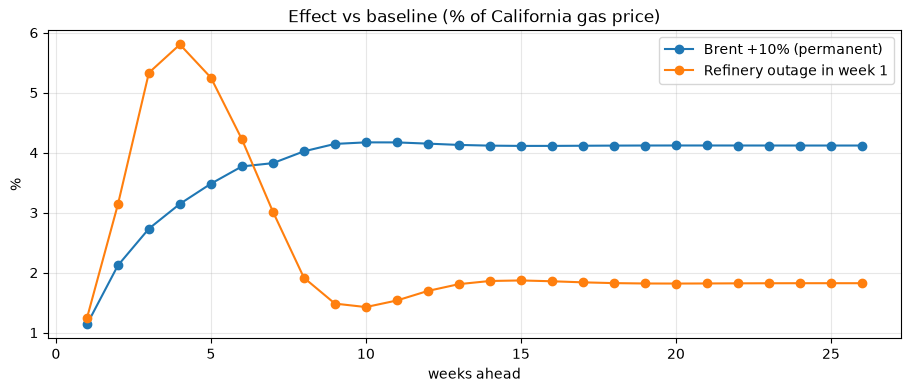

,Brent +10% (permanent),Refinery outage in week 1
1,1.14,1.24
2,2.12,3.14
4,3.15,5.80
8,4.02,1.92
12,4.15,1.70
26,4.12,1.82


In [24]:
last_brent = df["brent"].iloc[-1]
base = event_scenario(h=26)["forecast"]
check = pd.DataFrame({
    "Brent +10% (permanent)": event_scenario(h=26, brent_path=[last_brent * 1.1] * 26)["forecast"] / base - 1,
    "Refinery outage in week 1": event_scenario(h=26, outage_at=1)["forecast"] / base - 1,
})
check.index = range(1, 27)
ax = (check * 100).plot(marker="o", title="Effect vs baseline (% of California gas price)")
ax.set_xlabel("weeks ahead"); ax.set_ylabel("%"); plt.show()
(check.loc[[1, 2, 4, 8, 12, 26]] * 100).round(2)

### 8.2 Event scenarios: war, refinery outage, ceasefire

Scenario sizes are based on history: in the first month of the 2026 Iran war Brent rose about 55%; after the April ceasefire it fell from about 118 to about 70 by July (about −40%). Edit `SCENARIOS` to try others.

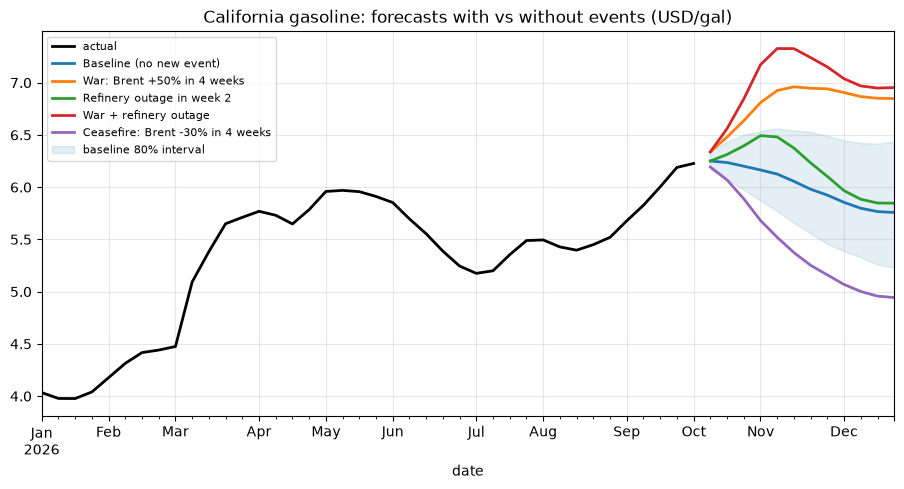

forecast             vs baseline            
weeks ahead                            4     8     12          4     8     12
scenario                                                                     
Baseline (no new event)              6.16  5.92  5.76        0.00  0.00  0.00
Ceasefire: Brent -30% in 4 weeks     5.68  5.16  4.94       -0.48 -0.76 -0.81
Refinery outage in week 2            6.49  6.10  5.85        0.33  0.18  0.09
War + refinery outage                7.17  7.15  6.95        1.01  1.23  1.20
War: Brent +50% in 4 weeks           6.81  6.94  6.85        0.64  1.02  1.09

In [25]:
def brent_ramp(mult, weeks, h=H):
    # Brent moves to last_brent * mult over `weeks` weeks, then stays there
    return last_brent * np.r_[np.linspace(1, mult, weeks + 1)[1:], np.repeat(mult, h - weeks)]

SCENARIOS = {
    "Baseline (no new event)": {},
    "War: Brent +50% in 4 weeks": dict(brent_path=brent_ramp(1.5, 4)),
    "Refinery outage in week 2": dict(outage_at=2),
    "War + refinery outage": dict(brent_path=brent_ramp(1.5, 4), outage_at=2),
    "Ceasefire: Brent -30% in 4 weeks": dict(brent_path=brent_ramp(0.7, 4)),
}
scen = {name: event_scenario(res=ardl_full, **kw) for name, kw in SCENARIOS.items()}  # same seed -> same shocks

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for name, s in scen.items():
    s["forecast"].plot(ax=ax, lw=2, label=name)
b0 = scen["Baseline (no new event)"]
ax.fill_between(b0.index, b0["lower80"], b0["upper80"], color="C0", alpha=0.12, label="baseline 80% interval")
ax.set_title("California gasoline: forecasts with vs without events (USD/gal)"); ax.legend(fontsize=8); plt.show()

rows = []
for name, s in scen.items():
    for w in (4, 8, 12):
        rows.append({"scenario": name, "weeks ahead": w, "forecast": s["forecast"].iloc[w - 1],
                     "vs baseline": s["forecast"].iloc[w - 1] - b0["forecast"].iloc[w - 1],
                     "80% interval": f"{s['lower80'].iloc[w - 1]:.2f} - {s['upper80'].iloc[w - 1]:.2f}"})
scen_table = pd.DataFrame(rows).pivot(index="scenario", columns="weeks ahead", values=["forecast", "vs baseline"]).round(2)
scen_table.to_csv(RES_DIR / "event_scenarios.csv")
scen_table

### 8.3 Brent price scenarios with `scenario()` (used by the dashboard's scenario tool)
Give future weekly Brent prices (USD/bbl) → get a California gasoline forecast with an 80% interval.
The proposal planned ARIMAX for this; we use the model above instead, for the reason explained in section 8.

"Brent flat" = crude stays at **today's price**; in the other scenarios crude moves to the target price over 4 weeks and then stays there.

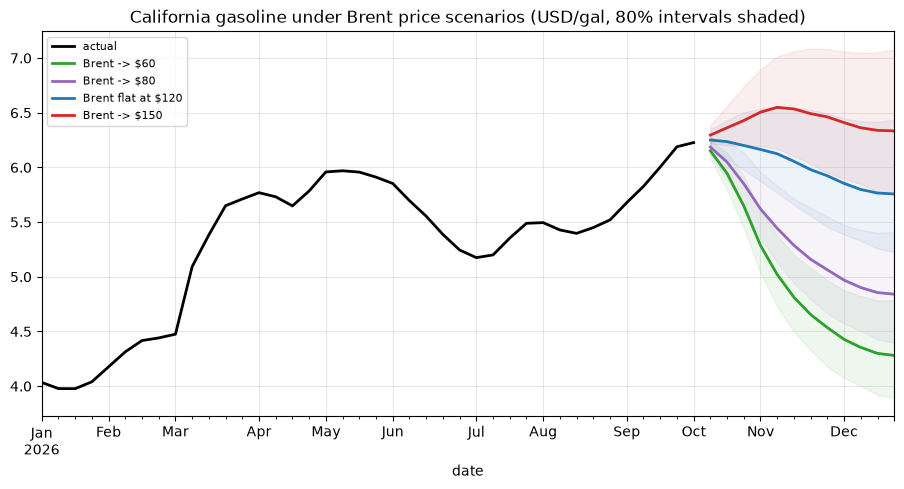

,4 weeks,8 weeks,12 weeks,12-week 80% interval
Brent -> $60,5.286412,4.535536,4.280591,3.89 - 4.78
Brent -> $80,5.620017,5.063701,4.840781,4.40 - 5.41
Brent flat at $120,6.164047,5.923107,5.757179,5.23 - 6.43
Brent -> $150,6.505131,6.461612,6.333599,5.75 - 7.08


In [26]:
def scenario(brent_path, outage_at=None, data=df):
    # brent_path: future weekly Brent prices (USD/bbl). outage_at: optional week of a refinery outage.
    # Returns CA gasoline forecast (USD/gal) with an 80% interval, indexed by date.
    res = ardl_full if data is df else None
    return event_scenario(data, h=len(brent_path), brent_path=np.asarray(brent_path, float),
                          outage_at=outage_at, res=res)

BRENT_TARGETS = [60, 80, round(last_brent), 150]   # USD/bbl
price_scen = {(f"Brent flat at ${t}" if t == round(last_brent) else f"Brent -> ${t}"):
              scenario(brent_ramp(t / last_brent, 4)) for t in BRENT_TARGETS}

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for (name, s), color in zip(price_scen.items(), ["C2", "C4", "C0", "C3"]):
    s["forecast"].plot(ax=ax, lw=2, color=color, label=name)
    ax.fill_between(s.index, s["lower80"], s["upper80"], color=color, alpha=0.08)
ax.set_title("California gasoline under Brent price scenarios (USD/gal, 80% intervals shaded)")
ax.legend(fontsize=8); plt.show()

brent_table = pd.DataFrame({name: {f"{w} weeks": s["forecast"].iloc[w - 1] for w in (4, 8, 12)}
                            | {"12-week 80% interval": f"{s['lower80'].iloc[-1]:.2f} - {s['upper80'].iloc[-1]:.2f}"}
                            for name, s in price_scen.items()}).T
brent_table.to_csv(RES_DIR / "brent_scenarios.csv")
brent_table

### 8.4 How accurate is this model's baseline forecast?
The `event_scenario()` baseline (no new events, Brent flat) is run through the same rolling-origin backtest and compared with the other models. If it is about as accurate as ARIMA, its scenario forecasts are more credible.

In [27]:
def ardl_ff(train, h):
    f = event_scenario(train, h, n_sims=500)
    f.index = range(1, h + 1)
    return f

forecasts["ardl"] = backtest("ardl", ardl_ff)
all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.sort_values(["horizon", "MAE"])

  ardl: origin 1/66 2025-06-30


  ardl: origin 21/66 2025-11-17


  ardl: origin 41/66 2026-04-06


  ardl: origin 61/66 2026-08-24


  ardl: origin 66/66 2026-09-28


n    MAE   RMSE    MAPE  Coverage80  DirAcc  \
horizon model                                                         
4       arima_fourier  63  0.218  0.312   4.112       0.810  71.429   
        arimax         63  0.223  0.331   4.210       0.714  74.603   
        combo          63  0.227  0.328   4.312       0.825  71.429   
        ardl           63  0.235  0.326   4.540       0.683  71.429   
        smean          63  0.236  0.311   4.601       0.794  63.492   
        timesfm        63  0.256  0.361   4.909       0.746  63.492   
        naive          63  0.270  0.384   5.233       0.794     NaN   
        chronos2       63  0.273  0.384   5.205       0.730  58.730   
        chronos_bolt   63  0.277  0.384   5.308       0.683  55.556   
        ets            63  0.281  0.378   5.374       0.841  63.492   
        snaive         63  0.631  0.848  11.421       0.841  57.143   
12      arima_fourier  55  0.410  0.581   7.526       0.745  80.000   
        smean          55  0.437  0.619   7.883       0.764  81.818   
        combo          55  0.469  0.690   8.512       0.727  70.909   
        ardl           55  0.476  0.638   8.694       0.636  74.545   
        arimax         55  0.503  0.681   9.190       0.636  70.909   
        chronos2       55  0.575  0.818  10.566       0.673  56.364   
        chronos_bolt   55  0.579  0.829  10.592       0.691  56.364   
        timesfm        55  0.582  0.820  10.697       0.709  54.545   
        naive          55  0.600  0.812  11.109       0.782     NaN   
        snaive         55  0.715  0.907  12.895       0.818  81.818   
        ets            55  0.725  0.904  13.502       0.836  41.818   

                       Skill_vs_naive  
horizon model                          
4       arima_fourier           0.806  
        arimax                  0.826  
        combo                   0.841  
        ardl                    0.868  
        smean                   0.871  
        timesfm                 0.948  
        naive                   1.000  
        chronos2                1.009  
        chronos_bolt            1.025  
        ets                     1.039  
        snaive                  2.335  
12      arima_fourier           0.683  
        smean                   0.728  
        combo                   0.783  
        ardl                    0.793  
        arimax                  0.839  
        chronos2                0.959  
        chronos_bolt            0.966  
        timesfm                 0.970  
        naive                   1.000  
        snaive                  1.192  
        ets                     1.208

## Output files
- `forecasts/<model>.csv`: each model's forecasts in the shared format from the proposal — scored by Member 3, read by Member 6's dashboard
- `results/metrics.csv`: MAE / RMSE / MAPE / skill / coverage
- `results/dm_tests.csv`: Diebold-Mariano tests
- `results/event_scenarios.csv`: scenario forecasts with vs without events
- `results/brent_scenarios.csv`: scenario forecasts for Brent at \$60 / \$80 / today's price / \$150

**Note**: the test period (July 2025 onward) includes the Phillips 66 closure, the Chevron fire and the 2026 Iran war. These events' dummies have no variation at the early rolling origins, so they are dropped automatically and enter the model only after the event happens.